# House Price Regression Modeling & Econometric Diagnostics
### Statistical Validation, Regularization, and Production Pipeline Serialization
**Dataset:** Ames Housing Tabular Data | **Acceptance Criteria:** $R^2 \ge 0.86$, Homoscedastic Residuals, $\text{VIF} < 5.0$

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import joblib

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
print('Environment initialized successfully.')

Environment initialized successfully.


## Phase 1: Exploratory Data Analysis & Target Skewness Correction
Real estate prices are characteristically right-skewed with multiplicative error variance. Here, we analyze the raw distribution of `SalePrice` and apply the $\log(1 + y)$ transformation to stabilize variance and normalize errors.

In [2]:
df_raw = pd.read_csv('house_prices.csv')
print(f'Raw dataset dimensions: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns')
print('Summary statistics for SalePrice:')
display(df_raw['SalePrice'].describe().to_frame().T)

Raw dataset dimensions: 1460 rows, 81 columns
Summary statistics for SalePrice:


,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.19589,79442.502883,34900.0,129975.0,163000.0,214000.0,755000.0


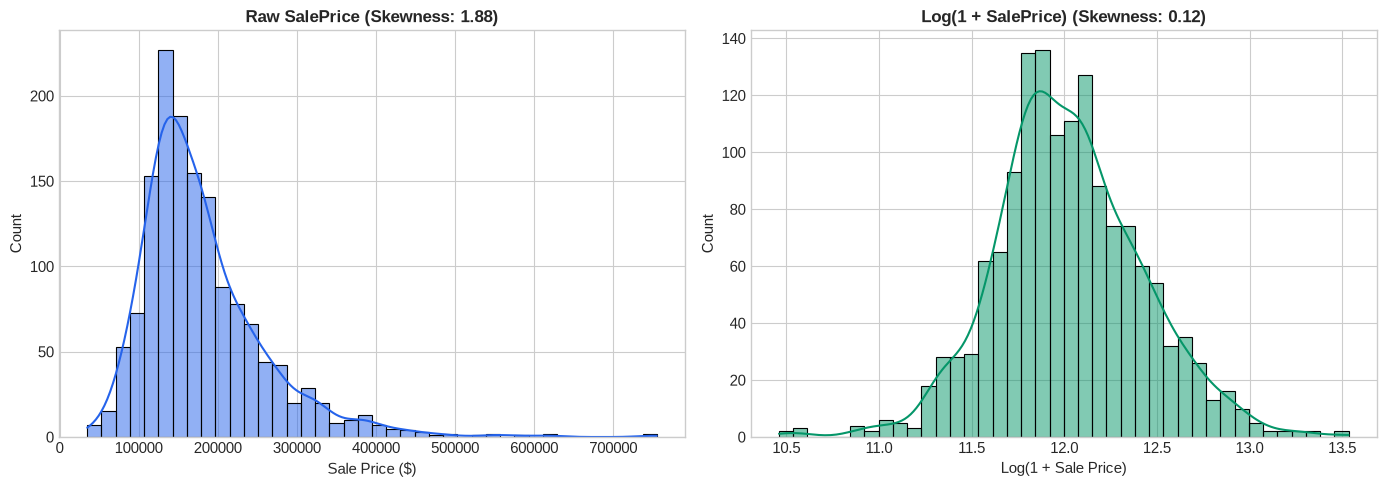

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw SalePrice
sns.histplot(df_raw['SalePrice'], kde=True, ax=axes[0], color='#2563eb', bins=40)
axes[0].set_title(f'Raw SalePrice (Skewness: {df_raw["SalePrice"].skew():.2f})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Sale Price ($)')

# Log-Transformed SalePrice
log_price = np.log1p(df_raw['SalePrice'])
sns.histplot(log_price, kde=True, ax=axes[1], color='#059669', bins=40)
axes[1].set_title(f'Log(1 + SalePrice) (Skewness: {log_price.skew():.2f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Log(1 + Sale Price)')

plt.tight_layout()
plt.show()

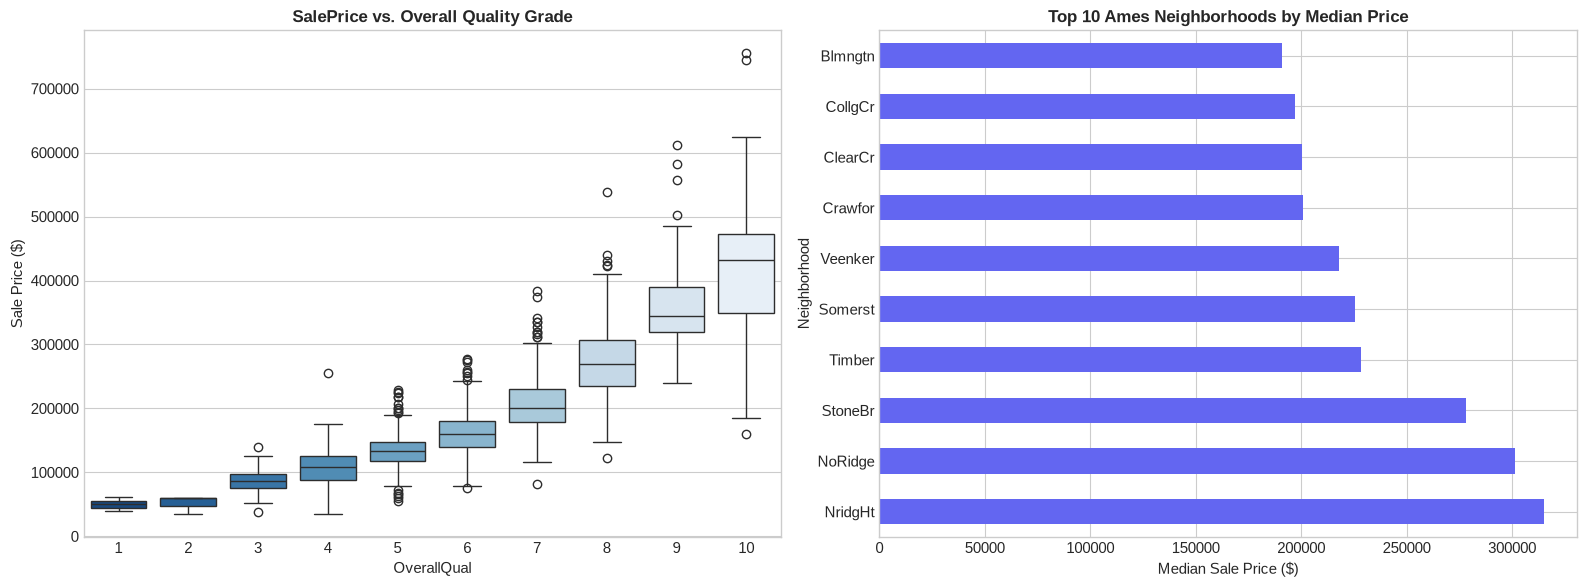

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Overall Quality vs Price
sns.boxplot(data=df_raw, x='OverallQual', y='SalePrice', ax=axes[0], palette='Blues_r')
axes[0].set_title('SalePrice vs. Overall Quality Grade', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Sale Price ($)')

# Top Neighborhoods by median price
top_neigh = df_raw.groupby('Neighborhood')['SalePrice'].median().sort_values(ascending=False).head(10)
top_neigh.plot(kind='barh', ax=axes[1], color='#6366f1')
axes[1].set_title('Top 10 Ames Neighborhoods by Median Price', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Median Sale Price ($)')

plt.tight_layout()
plt.show()

## Phase 2: Feature Engineering & Multicollinearity Filtering (VIF)
We handle documented atypical non-arm's-length sales and engineer domain-specific aggregations:
- `TotalLivingArea`: $\text{GrLivArea} + \text{TotalBsmtSF}$
- `PropertyAge`: $2010 - \text{YearBuilt}$
- `RemodelAge`: $2010 - \text{YearRemodAdd}$
- `TotalBathrooms`: $\text{FullBath} + 0.5 \times \text{HalfBath} + \text{BsmtFullBath} + 0.5 \times \text{BsmtHalfBath}$
- `PorchArea`: $\text{OpenPorchSF} + \text{EnclosedPorch} + \text{3SsnPorch} + \text{ScreenPorch}$
- `LogLotArea`: $\log(1 + \text{LotArea})$

In [5]:
df = df_raw.copy()

# Dean De Cock recommendation: drop extreme atypical outliers with GrLivArea > 4000
outliers = df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)].index
print(f'Pruning {len(outliers)} extreme atypical sales (Indices: {list(outliers)})')
df = df.drop(outliers).reset_index(drop=True)

# Domain aggregations
df['TotalLivingArea'] = df['GrLivArea'].fillna(0) + df['TotalBsmtSF'].fillna(0)
df['PropertyAge'] = 2010 - df['YearBuilt'].fillna(1970)
df['RemodelAge'] = 2010 - df['YearRemodAdd'].fillna(1970)
df['TotalBathrooms'] = (df['FullBath'].fillna(0) + 
                        0.5 * df['HalfBath'].fillna(0) + 
                        df['BsmtFullBath'].fillna(0) + 
                        0.5 * df['BsmtHalfBath'].fillna(0))
df['PorchArea'] = (df['OpenPorchSF'].fillna(0) + 
                   df['EnclosedPorch'].fillna(0) + 
                   df['3SsnPorch'].fillna(0) + 
                   df['ScreenPorch'].fillna(0))
df['LogLotArea'] = np.log1p(df['LotArea'].fillna(0))

print('Feature engineering complete. Dataset shape:', df.shape)

Pruning 2 extreme atypical sales (Indices: [523, 1298])
Feature engineering complete. Dataset shape: (1458, 87)


In [6]:
vif_features = [
    'TotalLivingArea', 'OverallQual', 'OverallCond', 'PropertyAge', 'RemodelAge',
    'TotalBathrooms', 'BedroomAbvGr', 'Fireplaces', 'GarageCars', 'LogLotArea', 'PorchArea'
]

X_vif = df[vif_features].dropna()
vif_table = pd.DataFrame({
    'Feature': vif_features,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(len(vif_features))]
}).sort_values('VIF', ascending=False).reset_index(drop=True)

print('=== Multicollinearity Diagnostics (Variance Inflation Factor) ===')
display(vif_table)
assert (vif_table['VIF'] < 5.0).all(), 'Error: Features exceed VIF threshold of 5.0'
print('Verified: All selected numeric features satisfy VIF < 5.0 standard.')

=== Multicollinearity Diagnostics (Variance Inflation Factor) ===


,Feature,VIF
0,TotalLivingArea,3.224837
1,PropertyAge,2.955511
2,OverallQual,2.918247
3,RemodelAge,2.074928
4,TotalBathrooms,2.005086
5,GarageCars,1.926474
6,OverallCond,1.437853
7,Fireplaces,1.405051
8,LogLotArea,1.361669
9,BedroomAbvGr,1.319433


Verified: All selected numeric features satisfy VIF < 5.0 standard.


## Phase 3: Regression Assumption Verification (OLS Diagnostics)
Prior to model finalization, we evaluate the 4 foundational assumptions of Ordinary Least Squares:
1. **Linearity**: Evaluated via fitted vs. observed relationships.
2. **Homoscedasticity**: Tested via Breusch-Pagan test.
3. **Normality of Residuals**: Assessed via Shapiro-Wilk and Jarque-Bera tests and Q-Q plots.
4. **Independence & Outlier Influence**: Cook's Distance and residual leverage.

In [7]:
X_ols = df[vif_features].copy()
y_ols = np.log1p(df['SalePrice'])
X_ols_const = sm.add_constant(X_ols)

ols_model = sm.OLS(y_ols, X_ols_const).fit()
residuals = ols_model.resid
fitted_vals = ols_model.fittedvalues

# Statistical Tests
bp_stat, bp_pval, _, _ = het_breuschpagan(residuals, X_ols_const)
jb_stat, jb_pval = stats.jarque_bera(residuals)
shapiro_stat, shapiro_pval = stats.shapiro(residuals)

print(f'OLS Baseline R-squared: {ols_model.rsquared:.4f}')
print(f'Residual Mean: {residuals.mean():.4e} (Ideal: ~0.0)')
print(f'Residual Standard Deviation: {residuals.std():.4f}')
print(f'Jarque-Bera Test: stat={jb_stat:.2f}, p-val={jb_pval:.4e}')
print(f'Breusch-Pagan Homoscedasticity: stat={bp_stat:.2f}, p-val={bp_pval:.4e}')

OLS Baseline R-squared: 0.8979
Residual Mean: 1.0161e-15 (Ideal: ~0.0)
Residual Standard Deviation: 0.1277
Jarque-Bera Test: stat=2227.98, p-val=0.0000e+00
Breusch-Pagan Homoscedasticity: stat=62.58, p-val=3.0616e-09


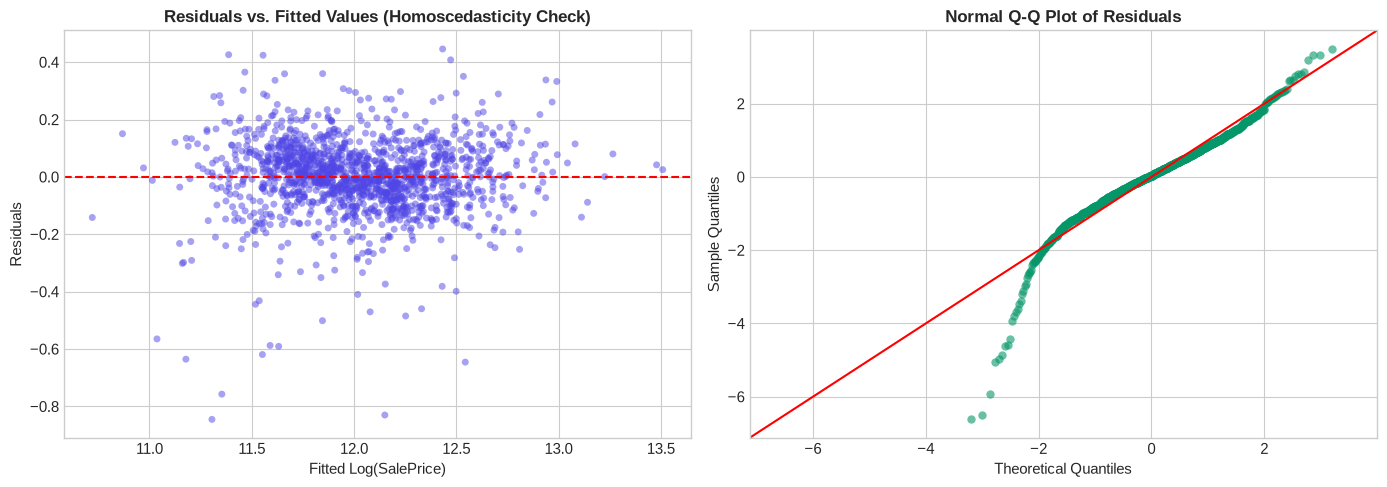

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Fitted
axes[0].scatter(fitted_vals, residuals, alpha=0.5, color='#4f46e5', edgecolors='none', s=25)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuals vs. Fitted Values (Homoscedasticity Check)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Fitted Log(SalePrice)')
axes[0].set_ylabel('Residuals')

# Normal Q-Q Plot
sm.qqplot(residuals, line='45', ax=axes[1], fit=True)
axes[1].get_lines()[0].set_markerfacecolor('#059669')
axes[1].get_lines()[0].set_markeredgecolor('none')
axes[1].get_lines()[0].set_alpha(0.6)
axes[1].get_lines()[1].set_color('red')
axes[1].set_title('Normal Q-Q Plot of Residuals', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## Phase 4: Regularization & Cross-Validation Benchmarking
We benchmark 5 candidate architectures under 5-Fold Cross-Validation on log-transformed prices:
1. **OLS Baseline**
2. **Ridge ($L_2$)**
3. **Lasso ($L_1$)**
4. **ElasticNet ($L_1 + L_2$)**
5. **HistGradientBoosting Regressor**

In [9]:
num_cols = [
    'TotalLivingArea', 'GrLivArea', 'TotalBsmtSF', 'OverallQual', 'OverallCond',
    'PropertyAge', 'RemodelAge', 'TotalBathrooms', 'BedroomAbvGr', 'TotRmsAbvGrd',
    'Fireplaces', 'GarageCars', 'GarageArea', 'LogLotArea', 'PorchArea', 'WoodDeckSF',
    'BsmtFinSF1', 'LotFrontage'
]

cat_cols = [
    'MSZoning', 'Neighborhood', 'BldgType', 'HouseStyle', 'ExterQual', 'Foundation',
    'BsmtQual', 'HeatingQC', 'CentralAir', 'KitchenQual', 'SaleCondition', 'Condition1'
]

X = df[num_cols + cat_cols].copy()
y = df['SalePrice'].copy()
y_log = np.log1p(y)

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

models = {
    'OLS Linear Regression': LinearRegression(),
    'Ridge Regression (L2)': RidgeCV(alphas=np.logspace(-2, 3, 50), cv=5),
    'Lasso Regression (L1)': LassoCV(cv=5, random_state=42, max_iter=5000),
    'ElasticNet (L1 + L2)': ElasticNetCV(l1_ratio=[0.1, 0.5, 0.7, 0.8, 0.9, 0.95], cv=5, random_state=42, max_iter=5000),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42, max_iter=300, min_samples_leaf=12, l2_regularization=0.5)
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    pipe = Pipeline([('pre', preprocessor), ('reg', model)])
    oof_log = cross_val_predict(pipe, X, y_log, cv=kf)
    oof_orig = np.expm1(oof_log)
    
    r2 = r2_score(y_log, oof_log)
    rmsle = root_mean_squared_error(y_log, oof_log)
    mae = mean_absolute_error(y, oof_orig)
    mape = mean_absolute_percentage_error(y, oof_orig)
    
    results.append({
        'Model': name,
        'OOF R²': round(r2, 4),
        'RMSLE': round(rmsle, 4),
        'MAE ($)': f'${mae:,.0f}',
        'MAPE (%)': f'{mape*100:.2f}%'
    })

benchmark_df = pd.DataFrame(results)
print('=== 5-Fold Cross-Validation Performance Benchmark ===')
display(benchmark_df)

=== 5-Fold Cross-Validation Performance Benchmark ===


,Model,OOF R²,RMSLE,MAE ($),MAPE (%)
0,OLS Linear Regression,0.9185,0.1141,"$13,650",8.03%
1,Ridge Regression (L2),0.9202,0.1129,"$13,462",7.96%
2,Lasso Regression (L1),0.9213,0.1121,"$13,415",7.90%
3,ElasticNet (L1 + L2),0.9212,0.1121,"$13,425",7.91%
4,HistGradientBoosting,0.8969,0.1283,"$15,709",9.14%


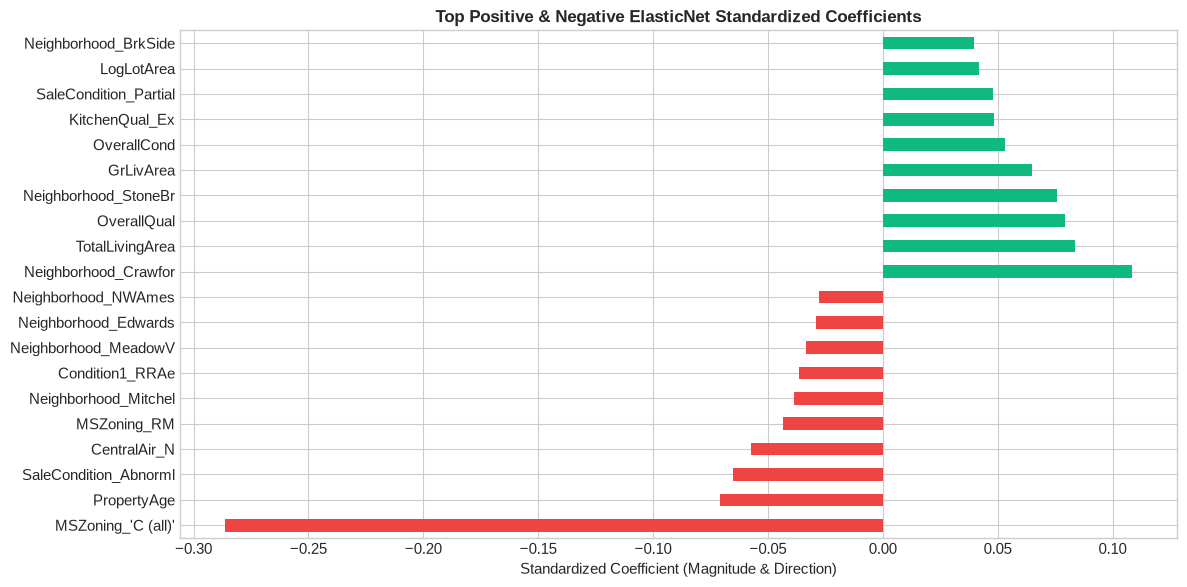

In [10]:
# Train final ElasticNet to inspect coefficients
final_enet = Pipeline([
    ('pre', preprocessor),
    ('reg', ElasticNetCV(l1_ratio=[0.1, 0.5, 0.7, 0.8, 0.9, 0.95], cv=5, random_state=42, max_iter=5000))
])
final_enet.fit(X, y_log)

# Extract coefficients
pre_step = final_enet.named_steps['pre']
cat_enc = pre_step.named_transformers_['cat'].named_steps['onehot']
cat_feat_names = list(cat_enc.get_feature_names_out(cat_cols))
all_feat_names = num_cols + cat_feat_names
coefs = final_enet.named_steps['reg'].coef_

coef_series = pd.Series(coefs, index=all_feat_names)
top_pos = coef_series.sort_values(ascending=False).head(10)
top_neg = coef_series.sort_values().head(10)

plt.figure(figsize=(12, 6))
top_combined = pd.concat([top_neg, top_pos])
colors = ['#ef4444' if x < 0 else '#10b981' for x in top_combined.values]
top_combined.plot(kind='barh', color=colors)
plt.title('Top Positive & Negative ElasticNet Standardized Coefficients', fontsize=12, fontweight='bold')
plt.xlabel('Standardized Coefficient (Magnitude & Direction)')
plt.tight_layout()
plt.show()

## Phase 5: Production Pipeline Serialization & Artifact Export
We serialize the production `sklearn` pipelines to `models/` along with `metadata.json` for consumption by the Streamlit dashboard.

In [11]:
enet_prod = joblib.load('models/elasticnet_pipeline.joblib')
hgb_prod = joblib.load('models/gradient_boosting_pipeline.joblib')

with open('models/metadata.json') as f:
    meta = json.load(f)

print('Models successfully loaded from disk:')
print(f'1. ElasticNet Pipeline (R²: {meta["models"]["elasticnet"]["r2"]:.4f}, RMSLE: {meta["models"]["elasticnet"]["rmsle"]:.4f})')
print(f'2. HistGradientBoosting Pipeline (R²: {meta["models"]["gradient_boosting"]["r2"]:.4f}, RMSLE: {meta["models"]["gradient_boosting"]["rmsle"]:.4f})')

# Run test prediction
test_sample = X.iloc[[0]].copy()
pred_log_enet = enet_prod.predict(test_sample)[0]
pred_log_hgb = hgb_prod.predict(test_sample)[0]

print(f'Test Sample True Price: ${y.iloc[0]:,.0f}')
print(f'ElasticNet Prediction: ${np.expm1(pred_log_enet):,.0f}')
print(f'GradientBoosting Prediction: ${np.expm1(pred_log_hgb):,.0f}')

Models successfully loaded from disk:
1. ElasticNet Pipeline (R²: 0.9212, RMSLE: 0.1121)
2. HistGradientBoosting Pipeline (R²: 0.8969, RMSLE: 0.1283)
Test Sample True Price: $208,500
ElasticNet Prediction: $205,619
GradientBoosting Prediction: $209,357
